In [56]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import yfinance as yf
import matplotlib.pyplot as plt

In [57]:
# Names are intentionally biased towards names with a history of
# large daily swings and volatility. The results will not be 
# representitive of the overall market. The goal is to display
# the drift.
tickers = [
    "NVDA", "AMD", "MU", "INTC", "MRVL",           # Semiconductors
    "CRWD", "DDOG", "OKTA", "TWLO", "DOCU", "ZM",  # Software & Cloud
    "META", "NFLX", "SNAP", "PINS", "ROKU",        # Web/Media
    "TSLA", "AMZN", "ETSY", "CVNA", "PTON",        # Consumer & Retail
    "MRNA", "ENPH", "PYPL", "BA",                  # Other
]

In [58]:
eps = pd.concat(
    {t: yf.Ticker(t).get_earnings_dates(limit=40) for t in tickers}, names=["ticker", "ann"]
).reset_index()
eps = eps.dropna(subset=["EPS Estimate", "Reported EPS"])
eps = eps[eps.ann >= pd.Timestamp("2020-01-01", tz="America/New_York")]

rel = pd.read_csv("data/releases.csv")
rel["accepted"] = pd.to_datetime(rel.acceptance, utc=True).dt.tz_convert("America/New_York")
ev = pd.merge_asof(
    eps.sort_values("ann"),
    rel.sort_values("accepted"),
    left_on="ann",
    right_on="accepted",
    by="ticker",
    direction="nearest",
    tolerance=pd.Timedelta("2D"),
)
ev["public"] = ev.accepted.fillna(ev.ann)
ev[["ticker", "ann", "EPS Estimate", "Reported EPS", "Surprise(%)", "n_words", "n_pos", "n_neg",]].head()

,ticker,ann,EPS Estimate,Reported EPS,Surprise(%),n_words,n_pos,n_neg
0,NFLX,2020-01-21 16:00:00-05:00,0.05,0.13,147.95,2507.0,37.0,7.0
1,INTC,2020-01-23 16:00:00-05:00,1.25,1.52,21.40,1976.0,26.0,21.0
2,AMD,2020-01-28 16:00:00-05:00,0.31,0.32,4.60,1842.0,18.0,65.0
3,BA,2020-01-29 07:00:00-05:00,-1.18,-2.33,-97.58,2128.0,6.0,42.0
4,TSLA,2020-01-29 16:00:00-05:00,0.12,0.14,17.76,3282.0,40.0,34.0


In [59]:
px = yf.download(tickers + ["SPY"], start="2019-11-01", auto_adjust=True, progress=False)["Close"]
ret = px.pct_change()
ab = ret[tickers].sub(ret["SPY"], axis=0)

In [60]:
# Day 0 is the first close after the news: the same day for releases before 16:00, else the next.

h = 40
t = ev.public.dt.tz_localize(None)
day = t.dt.normalize()
ev["quarter"] = day.dt.to_period("Q")
ev["day0"] = np.where(
    t.dt.hour >= 16, px.index.searchsorted(day, "right"), px.index.searchsorted(day, "left")
)
ev = ev[ev.day0 + h < len(px)].reset_index(drop=True)

r, c = ev.day0.to_numpy(), ab.columns.get_indexer(ev.ticker)
A = ab.to_numpy()
ev["sue"] = (ev["Reported EPS"] - ev["EPS Estimate"]) / px[tickers].to_numpy()[r - 1, c]
ev["jump"] = A[r, c]
car = pd.DataFrame(
    np.cumsum(A[r[:, None] + np.arange(1, h + 1), c[:, None]], axis=1),
    columns=range(1, h + 1),
)

keep = car.notna().all(axis=1) & ev.jump.notna() & (ev.sue != 0)
ev, car = ev[keep].reset_index(drop=True), car[keep].reset_index(drop=True)
ev["q"] = pd.qcut(ev.sue, 5, labels=range(1, 6))
print(f"{len(ev)} events, {(ev.sue < 0).mean():.0%} with a negative surprise")

637 events, 19% with a negative surprise


In [61]:
by_q = pd.concat(
    [
        ev.groupby("q", observed=True).agg(
            events=("sue", "size"), SUE=("sue", "mean"), jump=("jump", "mean")
        ),
        car[[20, 40]].groupby(ev.q, observed=True).mean().add_prefix("CAR 1-"),
    ],
    axis=1,
)

print(by_q.round(3))

   events    SUE   jump  CAR 1-20  CAR 1-40
q                                          
1     128 -0.007 -0.031    -0.011    -0.015
2     127  0.000 -0.002    -0.002     0.023
3     127  0.001  0.009     0.018     0.036
4     127  0.002  0.003    -0.004     0.027
5     128  0.007  0.044     0.014     0.043


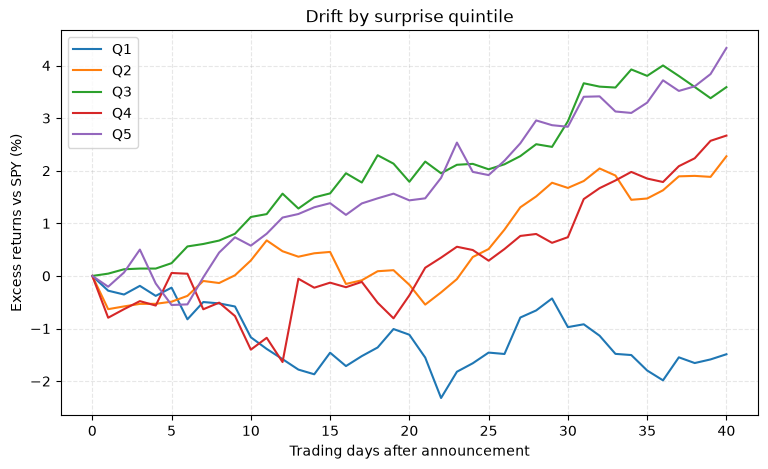

In [62]:
path = car.groupby(ev.q, observed=True).mean().T * 100
path.loc[0] = 0
path = path.sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
for q, line in path.items():
    ax.plot(line.index, line, label=f"Q{q}")
    
ax.set(
    xlabel="Trading days after announcement",
    ylabel="Excess returns vs SPY (%)",
    title="Drift by surprise quintile",
)
ax.legend()
ax.grid(alpha=0.3, linestyle="--")
plt.show()

In [63]:
# Tone is standardized against the firm's earlier releases only; ev is in announcement order.
ev["tone"] = (ev.n_pos - ev.n_neg) / ev.n_words
past = ev.groupby("ticker").tone
ev["z"] = (ev.tone - past.transform(lambda s: s.shift().expanding().mean())) / past.transform(
    lambda s: s.shift().expanding().std()
)

s = ev.z.notna()
side = np.sign(ev.sue[s])
agree = (side == np.sign(ev.z[s]))
signed = car[s].mul(side, axis=0)
print(f"{s.sum()} events with a tone score, {agree.mean():.0%} agree")

583 events with a tone score, 51% agree


In [64]:
by_agree = pd.concat(
    [
        side.groupby(agree).agg(events="size", long=lambda x: (x > 0).mean()),
        ev.jump[s].mul(side).groupby(agree).mean().rename("jump"),
        signed[[20, 40]].groupby(agree).mean().add_prefix("CAR 1-"),
    ],
    axis=1,
)

print(by_agree.round(3))

       events   long   jump  CAR 1-20  CAR 1-40
False     283  0.827  0.008     0.009     0.023
True      300  0.803  0.018     0.009     0.030


In [65]:
for d in (20, 40):
    fit = sm.OLS(signed[d], sm.add_constant((agree).astype(float))).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(ev.quarter[s])[0]}
    )
    print(f"CAR 1-{d}: drift(agree) - drift(disagree) = {fit.params.iloc[-1]:.2%} (t {fit.tvalues.iloc[-1]:.2f})")

CAR 1-20: drift(agree) - drift(disagree) = -0.01% (t -0.01)
CAR 1-40: drift(agree) - drift(disagree) = 0.75% (t 0.46)


### Discussion

Results show the Q1 and Q5 extremes drift with the surprise direction. All of the middle quintiles in this hand-picked sample also drift up.
Considering the direction of sentiment scores, the set that agrees with the surprise is observed to have about double the jump of the disagreeing set.
However, both 1-20 and 1-40 CAR show no significant difference between the groups. This indicates that the sentiment is priced in very quickly and the extended drift is not statistically attributable to it.

__Average 40-Day Drift Spread:__

| Quintile | 1-40 CAR |
|----------|----------|
| Q1 | -1.5% |
| Q2 | 2.3% |
| Q3 | 3.6% |
| Q4 | 2.7% |
| Q5 | 4.3% |
| __Q5 - Q1__ | __5.8%__ |

&nbsp;

__On Underreaction:__ 

The sample being used for this task was picked to be reactive through high volatility. The selection bias necessarily plays a role in the findings regarding jumps. The underlying drift is slow and lasts for weeks, as described in Lesson 6. However, seeing the comparative difference in jumps between the agree and disagree groups, we can't conclude that this sample is notably slow to react to text. A sentiment moving with the surprise is observed in price at day-0.